In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/data (1).csv')
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (6588, 4)


,Country Name,Country Code,Year,Value
0,Arab World,ARB,1990,7.344358
1,Arab World,ARB,1991,7.284093
2,Arab World,ARB,1992,6.912966
3,Arab World,ARB,1993,6.737793
4,Arab World,ARB,1994,6.914192



Column names:
['Country Name', 'Country Code', 'Year', 'Value']

Missing values:
Country Name    0
Country Code    0
Year            0
Value           0
dtype: int64


In [2]:
df.info()
display(df.describe())
print("Duplicate rows:", df.duplicated().sum())
print("Year range:", df['Year'].min(), "-", df['Year'].max())
print("Unique country names:", df['Country Name'].nunique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6588 entries, 0 to 6587
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country Name  6588 non-null   object 
 1   Country Code  6588 non-null   object 
 2   Year          6588 non-null   int64  
 3   Value         6588 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 206.0+ KB


,Year,Value
count,6588.000000,6588.000000
mean,2002.627505,31.013481
std,7.489255,30.162064
min,1990.000000,0.000000
25%,1996.000000,4.695936
50%,2003.000000,20.459103
75%,2009.000000,53.456452
max,2015.000000,98.342602


Duplicate rows: 0
Year range: 1990 - 2015
Unique country names: 259


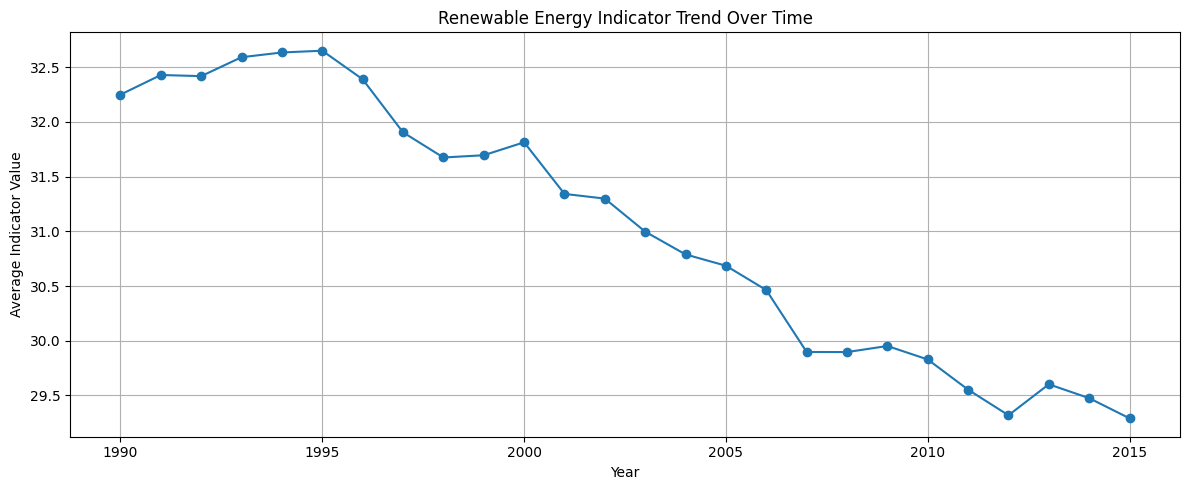

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate the average value for each year
yearly_trend = df.groupby("Year")["Value"].mean()

# Plot the trend
plt.figure(figsize=(12, 5))
plt.plot(yearly_trend.index, yearly_trend.values, marker="o")

plt.title("Renewable Energy Indicator Trend Over Time")
plt.xlabel("Year")
plt.ylabel("Average Indicator Value")
plt.grid(True)
plt.tight_layout()
plt.show()


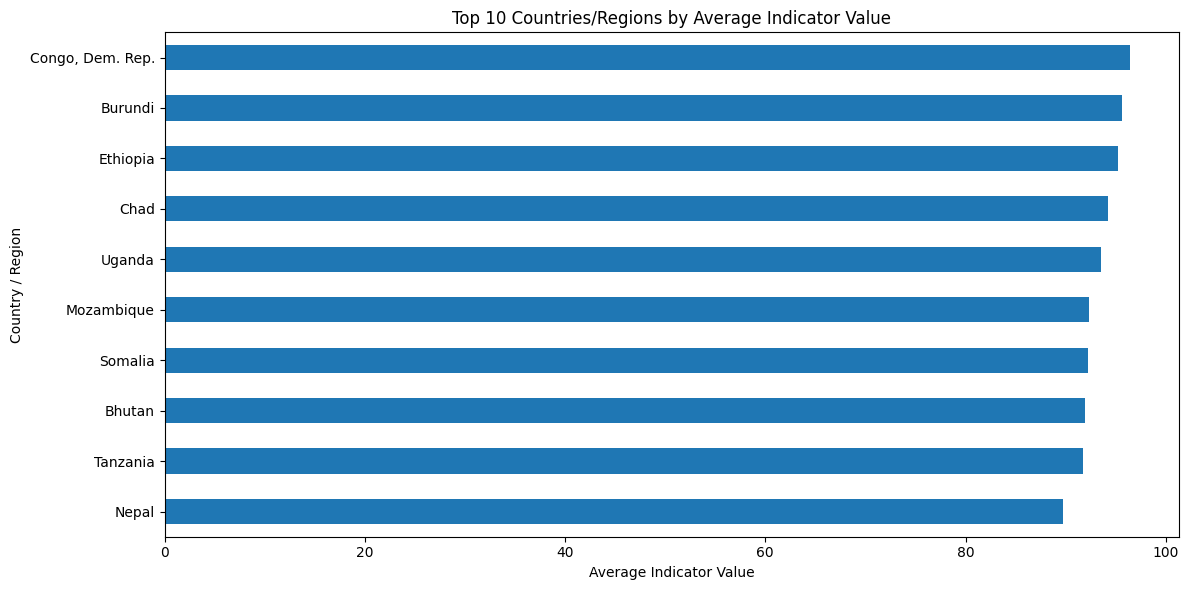

,Country Name,Value
0,"Congo, Dem. Rep.",96.467979
1,Burundi,95.591268
2,Ethiopia,95.206988
3,Chad,94.280364
4,Uganda,93.559658
5,Mozambique,92.335659
6,Somalia,92.213738
7,Bhutan,91.919649
8,Tanzania,91.714857
9,Nepal,89.766371


In [4]:
# Calculate average indicator value for each country
country_avg = (
    df.groupby("Country Name")["Value"]
    .mean()
    .sort_values(ascending=False)
)
# Select the top 10 entries
top_10 = country_avg.head(10)
# Create a bar chart
plt.figure(figsize=(12, 6))
top_10.sort_values().plot(kind="barh")
plt.title("Top 10 Countries/Regions by Average Indicator Value")
plt.xlabel("Average Indicator Value")
plt.ylabel("Country / Region")
plt.tight_layout()
plt.show()
display(top_10.reset_index())


In [5]:
print("Missing values before cleaning:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
df = df.dropna(
    subset=["Country Name", "Year", "Value"]
)
df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
df = df.dropna(subset=["Year", "Value"])
# Display cleaned dataset
print("\nDataset after cleaning:")
print("Rows and columns:", df.shape)
display(df.head())
print("\nMissing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
Country Name    0
Country Code    0
Year            0
Value           0
dtype: int64

Duplicate rows: 0

Dataset after cleaning:
Rows and columns: (6588, 4)


,Country Name,Country Code,Year,Value
0,Arab World,ARB,1990,7.344358
1,Arab World,ARB,1991,7.284093
2,Arab World,ARB,1992,6.912966
3,Arab World,ARB,1993,6.737793
4,Arab World,ARB,1994,6.914192



Missing values after cleaning:
Country Name    0
Country Code    0
Year            0
Value           0
dtype: int64


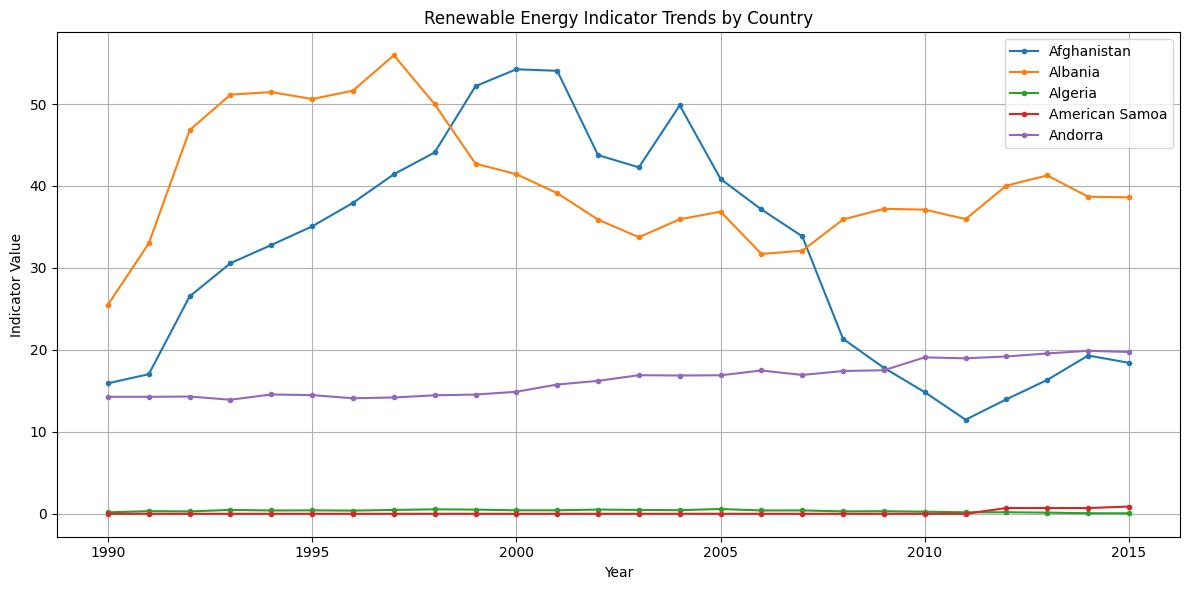

Countries included: ['Afghanistan', 'Albania', 'Algeria', 'American Samoa', 'Andorra']


In [6]:
# Select countries with the most available records
country_counts = df.groupby("Country Name")["Year"].nunique()
aggregates = [
    "Arab World",
    "World",
    "High income",
    "Low income",
    "Middle income",
    "European Union",
    "Euro area"
]
valid_counts = country_counts.drop(
    labels=[c for c in aggregates if c in country_counts.index],
    errors="ignore"
)
selected_countries = valid_counts.sort_values(
    ascending=False
).head(5).index.tolist()
# Plot trends for the selected countries
plt.figure(figsize=(12, 6))
for country in selected_countries:
    country_data = df[df["Country Name"] == country].sort_values("Year")
    plt.plot(
        country_data["Year"],
        country_data["Value"],
        marker="o",
        markersize=3,
        label=country
    )
plt.title("Renewable Energy Indicator Trends by Country")
plt.xlabel("Year")
plt.ylabel("Indicator Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
print("Countries included:", selected_countries)

Correlation Matrix:


,Year,Value
Year,1.00000,-0.03777
Value,-0.03777,1.00000


Correlation between Year and Value: -0.038


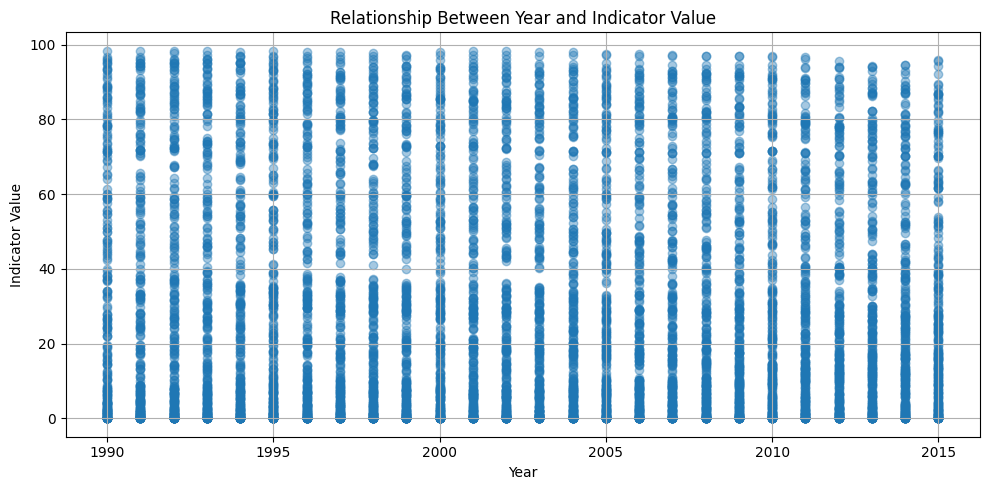

In [7]:
# Calculate correlation between Year and Value
correlation = df[["Year", "Value"]].corr()
print("Correlation Matrix:")
display(correlation)
print("Correlation between Year and Value:",
      round(correlation.loc["Year", "Value"], 3))
# Visualize the relationship
plt.figure(figsize=(10, 5))
plt.scatter(df["Year"], df["Value"], alpha=0.4)
plt.title("Relationship Between Year and Indicator Value")
plt.xlabel("Year")
plt.ylabel("Indicator Value")
plt.grid(True)
plt.tight_layout()
plt.show()

In [8]:

# Project Summary

print("=" * 45)
print("RENEWABLE ENERGY ADOPTION ANALYSIS")
print("=" * 45)

print("\n1. Dataset Information")
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Countries/regions:", df["Country Name"].nunique())
print("Start year:", int(df["Year"].min()))
print("End year:", int(df["Year"].max()))

print("\n2. Indicator Statistics")
print("Average value:", round(df["Value"].mean(), 3))
print("Median value:", round(df["Value"].median(), 3))
print("Minimum value:", round(df["Value"].min(), 3))
print("Maximum value:", round(df["Value"].max(), 3))

print("\n3. Highest Average Values")
display(
    df.groupby("Country Name")["Value"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print("\n4. Lowest Average Values")
display(
    df.groupby("Country Name")["Value"]
    .mean()
    .sort_values()
    .head(10)
    .reset_index()
)


RENEWABLE ENERGY ADOPTION ANALYSIS

1. Dataset Information
Total records: 6588
Total columns: 4
Countries/regions: 259
Start year: 1990
End year: 2015

2. Indicator Statistics
Average value: 31.013
Median value: 20.459
Minimum value: 0.0
Maximum value: 98.343

3. Highest Average Values


,Country Name,Value
0,"Congo, Dem. Rep.",96.467979
1,Burundi,95.591268
2,Ethiopia,95.206988
3,Chad,94.280364
4,Uganda,93.559658
5,Mozambique,92.335659
6,Somalia,92.213738
7,Bhutan,91.919649
8,Tanzania,91.714857
9,Nepal,89.766371



4. Lowest Average Values


,Country Name,Value
0,Qatar,0.0
1,Cayman Islands,0.0
2,Oman,0.0
3,Northern Mariana Islands,0.0
4,Palau,0.0
5,Antigua and Barbuda,0.0
6,Guam,0.0
7,Gibraltar,0.0
8,Tuvalu,0.0
9,Bahrain,0.0
